In [16]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from keras.layers import Input
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Flatten

In [9]:
# Load data from Keras datasets
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()
X_train = X_train/256
X_test = X_test/256

print("   ---- Data Information ----")
print(f"Pixel Size : {X_train.shape[1]} X {X_train.shape[2]}")
print(f"Number of training samples: {len(X_train)}")
print(f"Number of test samples: {len(X_test)}")

   ---- Data Information ----
Pixel Size : 28 X 28
Number of training samples: 60000
Number of test samples: 10000


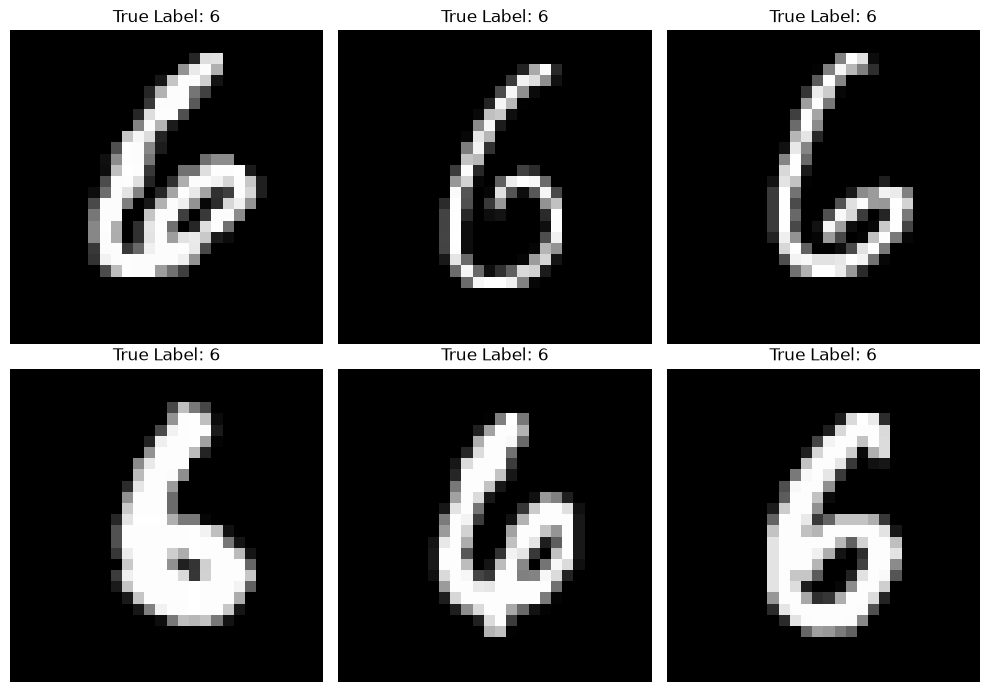

In [31]:
target_number = 6

if np.any(y_train == target_number):
    
    idx_found = np.where(y_train == target_number)[0] # Gives 1-D Array of indices 
    
    fig, axes = plt.subplots(2,3 ,figsize=(10, 7))
    axes = axes.flatten() # flatten to easily iterate
    
    for i in range(6):
        idx = idx_found[i]
        ax = axes[i]
        ax.imshow(X_train[idx], cmap='gray')
        ax.set_title(f'True Label: {y_train[idx]}', fontsize=12)
        ax.axis('off')
        
    plt.tight_layout()
    plt.show()    
else:
    print("Not Found!")    

# Baseline Kerals Model


In [71]:
model = Sequential()
model.add(Input(shape=(28, 28)))
model.add(Flatten())
model.add(Dense(200, activation='relu'))
model.add(Dense(100, activation='relu'))
model.add(Dense(10, activation='softmax'))

In [72]:
model.summary()

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_4 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 200)            │       157,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 100)            │        20,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 178,110 (695.74 KB)

 Trainable params: 178,110 (695.74 KB)

 Non-trainable params: 0 (0.00 B)

In [73]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

Model_hist = model.fit(X_train, y_train, epochs=20, batch_size=32, validation_split=0.2)

Epoch 1/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 747us/step - accuracy: 0.9286 - loss: 0.2428 - val_accuracy: 0.9597 - val_loss: 0.1302
Epoch 2/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 683us/step - accuracy: 0.9698 - loss: 0.0987 - val_accuracy: 0.9628 - val_loss: 0.1234
Epoch 3/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 706us/step - accuracy: 0.9780 - loss: 0.0679 - val_accuracy: 0.9641 - val_loss: 0.1096
Epoch 4/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 701us/step - accuracy: 0.9843 - loss: 0.0484 - val_accuracy: 0.9718 - val_loss: 0.1020
Epoch 5/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 684us/step - accuracy: 0.9871 - loss: 0.0393 - val_accuracy: 0.9685 - val_loss: 0.1221
Epoch 6/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 684us/step - accuracy: 0.9893 - loss: 0.0318 - val_accuracy: 0.9689 - val_loss: 0.1166
Epoch 7/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 684us/step - accuracy: 0.9920 - loss: 0.0246 - val_accuracy: 0.9755 - val_loss: 0.0973
Epoch 8/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 705us/step - accuracy: 0.9925 -

In [74]:
y_prob = model.predict(X_test)
y_pred = np.argmax(y_prob, axis=1)
y_pred

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 304us/step


array([7, 2, 1, ..., 4, 5, 6], shape=(10000,))

In [75]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test, y_pred)

0.9776

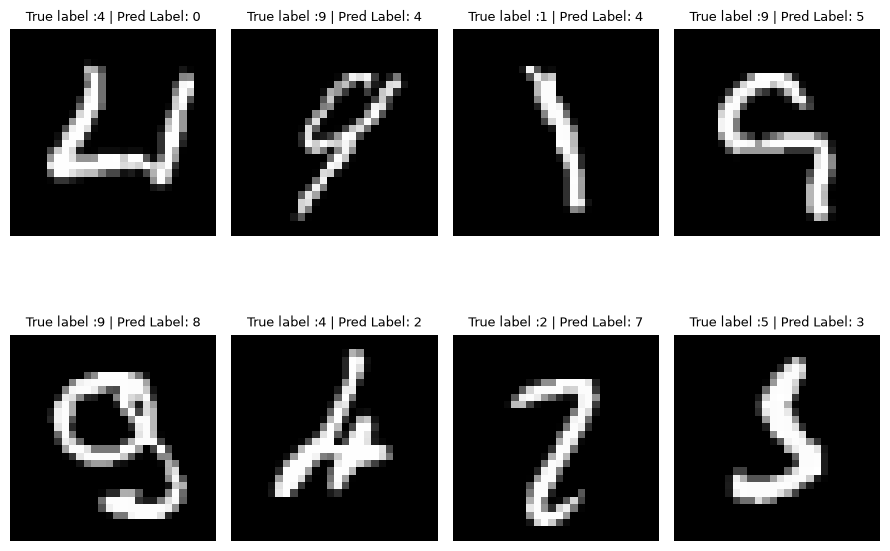

In [76]:
incorr_idx = np.where(y_pred != y_test)[0]# Gives 1-D Array of indices 
    
fig, axes = plt.subplots(2,4 ,figsize=(9, 7))
axes = axes.flatten() # flatten to easily iterate

for i in range(8):
    idx = incorr_idx[i]
    
    ax = axes[i]
    ax.imshow(X_test[idx], cmap='gray')
    ax.set_title(f'True label :{y_test[idx]} | Pred Label: {y_pred[idx]}', fontsize=9)
    ax.axis('off')
        
plt.tight_layout()
plt.show()  

# ANN Implementation from scratch

In [49]:
def init_parameters(dims, seed = 42):
    
    rng = np.random.RandomState(seed)
    parameters = {}
    
    # Xavier normal initialization to keep weights at a reasonable scale.
    
    for l in range(1, len(dims)):
        fan_in = dims[l-1]
        fan_out = dims[l]
        
        scaler = np.sqrt(2 / (fan_in + fan_out))
        
        # Mean = 0, STD = scaler and shape = (fan_in, fan_out)
        parameters[f"W{l}"] = rng.normal(0, scaler, (fan_in, fan_out))
        parameters[f"b{l}"] = np.zeros((1, fan_out))
    
    return parameters

In [91]:
p = init_parameters([784,128 ,100, 10])
print("Shape of b1 :", p['b1'].T.shape)
p

Shape of b1 : (128, 1)


{'W1': array([[ 2.32607714e-02, -6.47481914e-03,  3.03307948e-02, ...,
          1.02577483e-01, -4.63861134e-02, -2.65193209e-02],
        [ 4.66660273e-03, -2.35774077e-02, -7.26164684e-02, ...,
          4.83496157e-02, -7.11510176e-02, -2.26763381e-02],
        [ 5.93285503e-02, -3.31396590e-02,  2.07837490e-02, ...,
         -2.80691324e-02, -9.94605300e-02, -2.46207347e-02],
        ...,
        [ 3.11177977e-02, -2.31000149e-02,  5.28348163e-05, ...,
          7.64568110e-02,  8.45855189e-03, -2.08216788e-02],
        [-3.86576549e-02,  5.59464939e-02, -8.07880583e-03, ...,
          2.16142090e-02,  3.02666938e-02,  2.35225488e-02],
        [-1.99345192e-02, -1.91986034e-02, -5.67230845e-04, ...,
          5.75747488e-02,  7.54407175e-02,  6.50266877e-02]],
       shape=(784, 128)),
 'b1': array([[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0

In [53]:
def activation_relu(z):
    return np.maximum(0, z)

def relu_gradient(z):
    return (z > 0).astype(int)


In [107]:
def linear_forward(A, W, b):
    Z = W.T @ A + b.T
    return Z

In [131]:
X_train[1].shape

(28, 28)

In [80]:
A = np.atleast_1d(X_train[0])
A.shape

(28, 28)

In [133]:
X = X_train.reshape(X_train.shape[0], -1).T
X

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(784, 60000))

In [99]:
p['b1'].ravel().shape

(128,)

In [93]:
p['W1'].shape

(784, 128)

In [105]:
p['b1'].T.shape

(128, 1)

In [106]:
p['W1'].T @ X  + p['b1'].T

array([[ 0.29885455,  0.03282381, -0.20229115, ...,  0.12357769,
        -0.04551201,  0.43693482],
       [ 0.13399174,  0.75730311, -0.33600653, ...,  0.38627741,
         0.74527998,  0.36458013],
       [-0.25421487,  0.02812071,  0.14210534, ..., -0.11803441,
        -0.56240755, -0.72405822],
       ...,
       [ 0.15623105,  0.36906997, -0.1329271 , ...,  0.48607067,
        -0.12153674,  0.47400862],
       [ 0.34490991,  0.78209692,  0.7491936 , ...,  0.31326616,
         0.29577571,  0.76311586],
       [ 0.07872776,  0.02037849,  0.11297468, ..., -0.55326919,
        -0.41721533, -0.89688641]], shape=(128, 60000))

In [112]:
z1 = linear_forward(X, p['W1'], p['b1'])
z1

array([[ 0.29885455,  0.03282381, -0.20229115, ...,  0.12357769,
        -0.04551201,  0.43693482],
       [ 0.13399174,  0.75730311, -0.33600653, ...,  0.38627741,
         0.74527998,  0.36458013],
       [-0.25421487,  0.02812071,  0.14210534, ..., -0.11803441,
        -0.56240755, -0.72405822],
       ...,
       [ 0.15623105,  0.36906997, -0.1329271 , ...,  0.48607067,
        -0.12153674,  0.47400862],
       [ 0.34490991,  0.78209692,  0.7491936 , ...,  0.31326616,
         0.29577571,  0.76311586],
       [ 0.07872776,  0.02037849,  0.11297468, ..., -0.55326919,
        -0.41721533, -0.89688641]], shape=(128, 60000))

In [114]:
z2 = linear_forward(z1, p['W2'], p['b2'])
z2

array([[-0.55081724,  0.09132937,  0.0241547 , ..., -0.01060193,
         0.19340013,  0.09955603],
       [-0.731108  , -0.38943093, -0.47079756, ..., -0.22458025,
         0.45172956, -0.17546273],
       [ 0.19306571,  1.140662  ,  0.02339746, ...,  0.14931111,
         0.64646389,  0.51294368],
       ...,
       [-0.13870071, -0.28104793,  0.24277776, ..., -0.19663216,
        -0.07097201, -0.1805539 ],
       [ 1.04811028,  0.39151348, -0.12163533, ...,  0.91245164,
        -0.21645916,  0.22148081],
       [-0.15611851, -0.17782024, -0.48102439, ..., -0.07626994,
         0.1194431 , -0.6251564 ]], shape=(100, 60000))

In [116]:
p['W3'].shape

(100, 10)

In [117]:
z3 = linear_forward(z2, p['W3'], p['b3'])
z3

array([[ 0.89150765,  0.00282999,  0.68956286, ...,  0.89119812,
         0.37931702,  0.19495092],
       [ 0.82947627,  0.42215175, -0.36029287, ...,  0.66289251,
         0.92075395,  0.22095347],
       [ 0.10724236,  0.38411572, -0.40240505, ..., -0.16934206,
         0.43816007, -0.6200229 ],
       ...,
       [-0.56795501, -0.17182559,  0.25427517, ..., -0.38180423,
        -0.2949327 , -0.44810664],
       [-0.35978023,  0.27009979,  0.34370165, ...,  0.0385653 ,
         0.10315766, -0.42601114],
       [-0.84080342, -0.98406997,  0.23047389, ..., -1.81937184,
        -0.46015026, -0.21990027]], shape=(10, 60000))

In [110]:
p['W2']

array([[-0.00751474,  0.07149746,  0.09953783, ...,  0.00621817,
         0.03673842,  0.01736059],
       [-0.04189343,  0.03870737,  0.10694415, ..., -0.03682921,
         0.04077162, -0.02681071],
       [ 0.02387403, -0.17985606, -0.00255862, ..., -0.14884839,
         0.00088282,  0.05030668],
       ...,
       [-0.12114674, -0.01715408,  0.04248856, ...,  0.00384139,
         0.10402657,  0.04993066],
       [ 0.01599343, -0.08825979, -0.00480111, ..., -0.01408719,
        -0.04039267,  0.016126  ],
       [ 0.0164029 , -0.01976379, -0.1927562 , ...,  0.07067484,
         0.01157242,  0.10359955]], shape=(128, 100))

In [134]:
def forward_propagation(X, params):
    
    # Number of layers in the network
    layers = len(params) // 2
    
    A = X_train.reshape(X_train.shape[0], -1).T
    cache = {'A0': A}
    
    for l in range(1, layers + 1):
        A_prev = A
        
        W = params[f"W{l}"]
        b = params[f"b{l}"]
        
        Z = linear_forward(A_prev, W, b)
        
        if l == layers:
            pass
        else:
            A = activation_relu(Z)
        
        cache[f"A{l}"], cache[f"Z{l}"] = A, Z
    
    return A, cache

In [136]:
y_hat, cache = forward_propagation(X_train, p)